# Basic Decision Trees Demo

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, KFold,
    cross_validate, cross_val_predict)
from sklearn.tree import (
    DecisionTreeClassifier, DecisionTreeRegressor,
    plot_tree, export_text)
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (
    accuracy_score, confusion_matrix, mean_squared_error)

df = pd.read_csv("decision_trees_demo.csv")
features = ["petal_length_cm", "petal_width_cm"]
X = df[features]
y = df["species"]
print("Feature shape:", X.shape, "Target shape:", y.shape)

Feature shape: (150, 2) Target shape: (150,)


I used two features from the text, features = ["petal_length_cm", "petal_width_cm"]. The target I used is this, y = df["species"]. Including the species in X makes the model look at the column of input and this may cause the model to read the answer without working it out. I do not believe the model would show it learned. Also the accuracy score could look higher without showing that the model learned from the petals.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
assert X_train.index.equals(y_train.index)
assert set(X_train.index).isdisjoint(X_test.index)
train = X_train.assign(species=y_train)
print("Development rows:", len(X_train))
print("Reserved test rows:", len(X_test))

Development rows: 120
Reserved test rows: 30


By going through the test results and then choosing features or settings, the choices can become tailored to it. The final test set is a fair check of the model chosen without seeing the test rows. If I make adjustments to the model until it does well on test flowers, the flowers won't be new to the model anymore. When the score ends up looking good it will not tell me how the model does when it sees new flowers.

In [17]:
print(train.head())
print(train.dtypes)
print("Missing values:\n", train.isna().sum())
print(train[features].describe().round(2))
counts = y_train.value_counts().sort_index()
print("Class counts:\n", counts)
majority_accuracy = counts.max() / len(y_train)
print("Majority baseline:", round(majority_accuracy, 3))
print("Two labeled rows per class:\n",
      train.groupby("species").head(2))

     petal_length_cm  petal_width_cm     species
8                1.4             0.2      setosa
106              4.5             1.7   virginica
76               4.8             1.4  versicolor
9                1.5             0.1      setosa
89               4.0             1.3  versicolor
petal_length_cm    float64
petal_width_cm     float64
species                str
dtype: object
Missing values:
 petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64
       petal_length_cm  petal_width_cm
count           120.00          120.00
mean              3.77            1.20
std               1.77            0.76
min               1.10            0.10
25%               1.60            0.30
50%               4.25            1.30
75%               5.10            1.80
max               6.90            2.50
Class counts:
 species
setosa        40
versicolor    40
virginica     40
Name: count, dtype: int64
Majority baseline: 0.333
Two labeled rows per class:
      petal_le

I noticed that each species has 40 flowers in the development set. A high accuracy score does not automictically mean the model learned anything, because the the classifier could score well just by predicting the same class every time, without it learning anything.

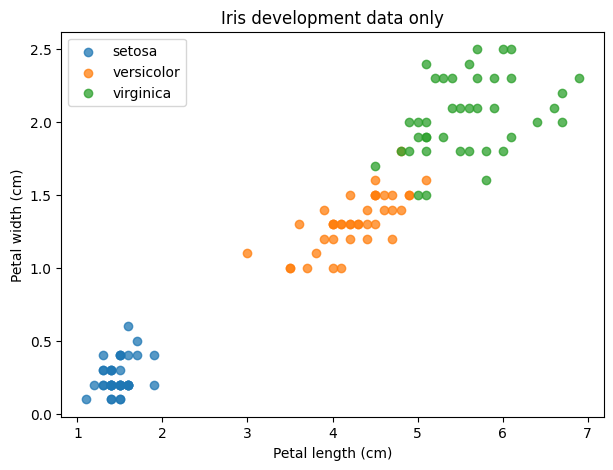

In [18]:
plt.figure(figsize=(7, 5))
for name, group in train.groupby("species"):
    plt.scatter(group[features[0]], group[features[1]],
                label=name, alpha=0.75)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris development data only")
plt.legend()
plt.show()

I would make the first split on petal length, around 2 to 3 cm, where setosa separates from the rest. The two species that are most likely to be confused are virginica and versicolor. In the chart their dots overlap.

In [19]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
tree = DecisionTreeClassifier(max_depth=2, random_state=42)
tree.fit(X_train, y_train)
print("Dummy training accuracy:", baseline.score(X_train, y_train))
print("Tree training accuracy:", tree.score(X_train, y_train))
print("Depth:", tree.get_depth(), "Leaves:", tree.get_n_leaves())
print(export_text(tree, feature_names=features))

Dummy training accuracy: 0.3333333333333333
Tree training accuracy: 0.9666666666666667
Depth: 2 Leaves: 3
|--- petal_length_cm <= 2.45
|   |--- class: setosa
|--- petal_length_cm >  2.45
|   |--- petal_width_cm <= 1.65
|   |   |--- class: versicolor
|   |--- petal_width_cm >  1.65
|   |   |--- class: virginica



If the petal length is 2.45 cm or less, the tree predicts setosa. Why a deeper tree can score so well is becuase a much deeper tree can ask many more questions, so it can fit the training flowers very closely and score very well on them. But that doesn’t mean it will do well on new flowers, because the score was measured on the flowers it was fitted to.

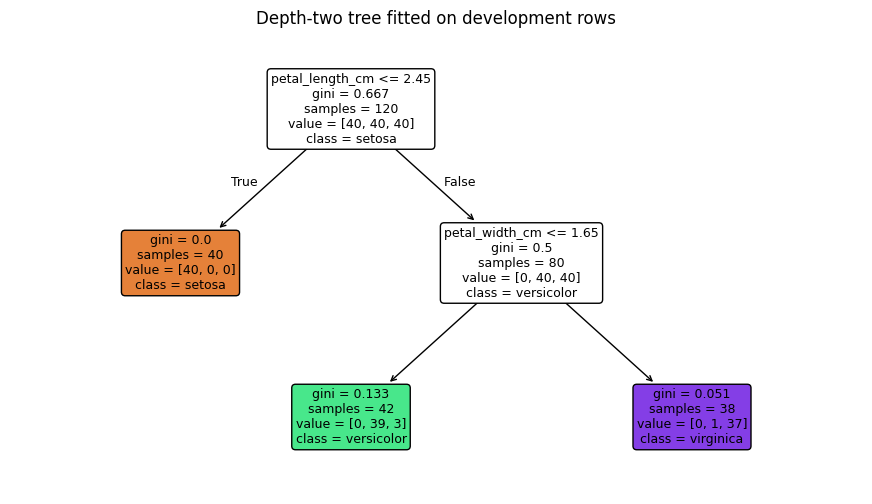

Predicted species: versicolor
Leaf ID: 3


In [20]:
plt.figure(figsize=(11, 6))
plot_tree(tree, feature_names=features,
          class_names=list(tree.classes_), filled=True,
          rounded=True, proportion=False, fontsize=9)
plt.title("Depth-two tree fitted on development rows")
plt.show()
flower = pd.DataFrame([[5.0, 1.5]], columns=features)
print("Predicted species:", tree.predict(flower)[0])
print("Leaf ID:", tree.apply(flower)[0])

When the petal length is 2.45 or less the answer is yes, in this case the answer was no because the flower was 5 cm and went down the false side. When the petal width is 1.65 or less the answer is yes. So in this case the flower's width was 1.5, the answer was yes and it went left. That ended in a leaf that predicts versicolor. A leaf is at the end of the path. Which means it has no question in its box and no arrows leaving the box this gives the prediction.

In [21]:
leaf_id = tree.apply(flower)[0]
in_leaf = tree.apply(X_train) == leaf_id
leaf_counts = y_train[in_leaf].value_counts().reindex(
    tree.classes_, fill_value=0)
probabilities = leaf_counts / leaf_counts.sum()
print(pd.DataFrame({"count": leaf_counts,
                    "probability": probabilities}))
print("predict_proba:", tree.predict_proba(flower)[0])
gini = 1 - np.sum(probabilities.to_numpy() ** 2)
print("Leaf Gini:", round(gini, 3))
assert np.allclose(probabilities, tree.predict_proba(flower)[0])

            count  probability
species                       
setosa          0     0.000000
versicolor     39     0.928571
virginica       3     0.071429
predict_proba: [0.         0.92857143 0.07142857]
Leaf Gini: 0.133


When training the flower with one training flower in the leaf, that flower's species has count of 1 out of 1, and when you divide 1 by 1 you get 1.0. All of the other species have a count of 0 out of 1. This is unreliable because one flower has very little evidence. The guide says very small leaves can give confident looking estimates based on little evidence. The leaf can say 100% pure for one species but that rests on one small example which may not hold for new flowers.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
candidates = {"dummy": DummyClassifier(strategy="most_frequent")}
for depth in [1, 2, 3, None]:
    for leaf_size in [1, 5]:
        name = f"depth={depth}, leaf={leaf_size}"
        candidates[name] = DecisionTreeClassifier(
            max_depth=depth, min_samples_leaf=leaf_size,
            random_state=42)
rows = []
for name, model in candidates.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring="accuracy", return_train_score=True)
    rows.append({"model": name,
                 "train": scores["train_score"].mean(),
                 "validation": scores["test_score"].mean(),
                 "spread": scores["test_score"].std()})
results = pd.DataFrame(rows).set_index("model")
print(results.round(3))

                    train  validation  spread
model                                        
dummy               0.333       0.333   0.000
depth=1, leaf=1     0.667       0.667   0.000
depth=1, leaf=5     0.667       0.667   0.000
depth=2, leaf=1     0.967       0.950   0.017
depth=2, leaf=5     0.967       0.950   0.017
depth=3, leaf=1     0.979       0.958   0.026
depth=3, leaf=5     0.969       0.950   0.017
depth=None, leaf=1  0.994       0.925   0.031
depth=None, leaf=5  0.969       0.950   0.017


The tree had no depth limit and scored 0.994 on the training flowers and scored 0.925 on the validation flowers. This gap suggests the tree memorized the training flowers, so it did worse on flowers it hadn't seen. Several of the settings were tied at 0.950 validation. The easiest one to explain is depth=2, because it asks at most two questions.

In [23]:
tree_results = results.drop(index="dummy")
winner = tree_results["validation"].idxmax()
chosen = candidates[winner]
trial = DecisionTreeClassifier(**{
    **chosen.get_params(), "criterion": "entropy"})
trial_scores = cross_validate(trial, X_train, y_train, cv=cv,
                              scoring="accuracy")
trial_mean = trial_scores["test_score"].mean()
print("Gini:", winner, tree_results.loc[winner, "validation"])
print("Entropy:", trial_mean)
if trial_mean > tree_results.loc[winner, "validation"]:
    chosen = trial
    winner += ", entropy"
frozen_classifier = chosen.fit(X_train, y_train)
print("Frozen classifier:", winner)

Gini: depth=3, leaf=1 0.9583333333333334
Entropy: 0.95
Frozen classifier: depth=3, leaf=1


Gini is at 0.958, entropy is at 0.95 and the selected model is depth=3, leaf=1. Gini won on these folds and it was kept because entropy didn't score higher. These two scores differ only by about 0.008. On the 120 flowers, that's roughly one flower, which is my estimate from the numbers. These scores come from one set of the five folds and a different split could change which one wins. The guide also says that Gini and entropy measure class mixing on different scales and neither is automatically better than the other.

In [24]:
oof = cross_val_predict(chosen, X_train, y_train, cv=cv)
labels = list(frozen_classifier.classes_)
matrix = confusion_matrix(y_train, oof, labels=labels)
print(pd.DataFrame(matrix, index=labels, columns=labels))
mistakes = train.loc[y_train.to_numpy() != oof].copy()
mistakes["predicted"] = oof[y_train.to_numpy() != oof]
print(mistakes.head(8))

            setosa  versicolor  virginica
setosa          40           0          0
versicolor       0          38          2
virginica        0           3         37
     petal_length_cm  petal_width_cm     species   predicted
106              4.5             1.7   virginica  versicolor
70               4.8             1.8  versicolor   virginica
83               5.1             1.6  versicolor   virginica
119              5.0             1.5   virginica  versicolor
126              4.8             1.8   virginica  versicolor


The two species that get the most confused are versicolor and virginica. All of the five mistakes are between them. 2 versicolor were predicted as virginica and 3 virginica were predicted as versicolor. Setosa was the only one that was never confused, with 40 of 40 correct. In step 4 from earlier I had guessed that the two most likely to get confused would be virginica and versicolor because they overlap. The matrix showed the same pair, so my guess was correct.

             x   target
count  160.000  160.000
mean    -0.002    0.081
std      0.288    0.073
min     -0.493   -0.057
25%     -0.267    0.022
50%     -0.025    0.070
75%      0.258    0.134
max      0.476    0.289


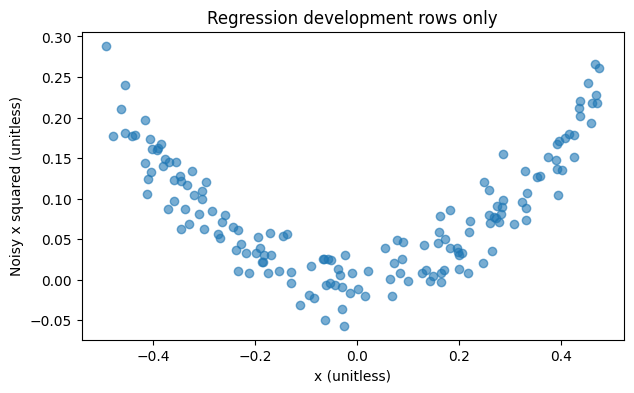

In [25]:
rng = np.random.default_rng(42)
X_reg = pd.DataFrame({"x": rng.uniform(-0.5, 0.5, 200)})
y_reg = X_reg["x"] ** 2 + rng.normal(0, 0.025, 200)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42)
print(Xr_train.assign(target=yr_train).describe().round(3))
plt.figure(figsize=(7, 4))
plt.scatter(Xr_train["x"], yr_train, alpha=0.6)
plt.xlabel("x (unitless)")
plt.ylabel("Noisy x squared (unitless)")
plt.title("Regression development rows only")
plt.show()

Accuracy counts the share of predictions that exactly match the true label. This works for species where an answer is right or wrong. Because a numeric target can take many values a prediction almost never matches exactly. And a prediction that is very close would still count as wrong, just the same as one that is really far off. The accuracy can't tell them apart. Instead a measure shows how far off the predictions are. The guide uses RMSE, which "measures typical error in the target's units" and gives larger misses more weight.

In [26]:
reg_models = {
    "mean": DummyRegressor(strategy="mean"),
    "depth 2": DecisionTreeRegressor(max_depth=2, random_state=42),
    "unrestricted": DecisionTreeRegressor(random_state=42),
    "leaf 10": DecisionTreeRegressor(min_samples_leaf=10,
                                     random_state=42)}
reg_cv = KFold(n_splits=5, shuffle=True, random_state=42)
reg_scores = {}
for name, model in reg_models.items():
    scores = cross_validate(model, Xr_train, yr_train, cv=reg_cv,
                            scoring="neg_root_mean_squared_error",
                            return_train_score=True)
    reg_scores[name] = -scores["test_score"].mean()
    print(name, "train RMSE", -scores["train_score"].mean(),
          "validation RMSE", reg_scores[name])
best_reg_name = min(reg_scores, key=reg_scores.get)
frozen_regressor = reg_models[best_reg_name].fit(Xr_train, yr_train)
print("Frozen regressor:", best_reg_name)

mean train RMSE 0.07321055940329217 validation RMSE 0.07336208580319721
depth 2 train RMSE 0.039554471880793016 validation RMSE 0.0428943691178364
unrestricted train RMSE -0.0 validation RMSE 0.0354185672010614
leaf 10 train RMSE 0.029427533832485024 validation RMSE 0.03382826586547792
Frozen regressor: leaf 10


The unrestricted tree is at 0.0 which is a great fit to the training rows. The lowest validation RMSE is leaf 10 at about 0.0338. The unrestricted tree's validation is at about 0.0354. So the model with the lowest training RMSE is not the one with the lowest validation RMSE. The unrestricted tree fit the training rows perfectly however it did worse on held-out folds, which is the same memorizing idea from steps 5 and 8.

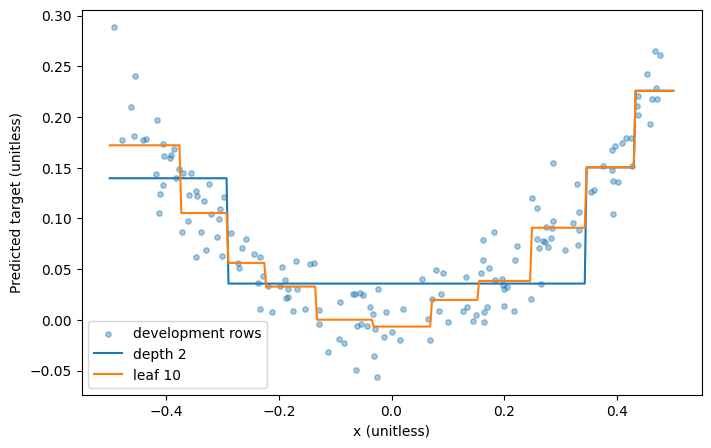

In [27]:
grid = pd.DataFrame({"x": np.linspace(-0.5, 0.5, 300)})
plt.figure(figsize=(8, 5))
plt.scatter(Xr_train["x"], yr_train, s=15, alpha=0.4,
            label="development rows")
for name in ["depth 2", "leaf 10"]:
    model = reg_models[name].fit(Xr_train, yr_train)
    plt.plot(grid["x"], model.predict(grid), label=name)
plt.xlabel("x (unitless)")
plt.ylabel("Predicted target (unitless)")
plt.legend()
plt.show()

This is where the models differ, near the bottom of the U shape, leaf 10 follows the dots down and sits lower, close to the lowest points. depth2 stays high and flat across the whole middle, because it has only a few wide steps. What the squared error registration tree predicts for targets 2,4 and 9 in one leaf is the average of them (2+4+9) / 3 = 5.

In [28]:
final_predictions = frozen_classifier.predict(X_test)
print("Final classifier:", winner)
print("Final test accuracy:", accuracy_score(y_test, final_predictions))
print("Final dummy accuracy:", baseline.score(X_test, y_test))
print("Final confusion matrix:\n",
      confusion_matrix(y_test, final_predictions, labels=labels))
reg_predictions = frozen_regressor.predict(Xr_test)
print("Final regressor:", best_reg_name)
print("Final regression RMSE:",
      mean_squared_error(yr_test, reg_predictions) ** 0.5)
reg_baseline = DummyRegressor().fit(Xr_train, yr_train)
print("Final mean-baseline RMSE:", mean_squared_error(
    yr_test, reg_baseline.predict(Xr_test)) ** 0.5)

Final classifier: depth=3, leaf=1
Final test accuracy: 0.9666666666666667
Final dummy accuracy: 0.3333333333333333
Final confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
Final regressor: leaf 10
Final regression RMSE: 0.03345240109117966
Final mean-baseline RMSE: 0.08043607809190362


The classifier is 0.967 vs the baseline's 0.333. It is far better than always guessing one species. The regressor is RMSE 0.0335 vs the baseline's 0.0804. Its error is less than half of the baseline's. One of the limitations of the test sets is that tests are small. With 30 flowers, one mistake moves the accuracy by about 0.033, so a different test set can give a different score.

The frozen classifier is depth=3, leaf=1, criterion Gini, chosen because it had the best validation accuracy of 0.958. The frozen regressor is leaf 10, which was chosen because it had the lowest validation RMSE of about 0.0338. On the final test rows, the classifier scored 0.967 vs a baseline of 0.333, and the regressor had an RMSE of 0.0335 vs 0.0804. One of the limitations is that the test sets are small.